In [1]:
import time
import seaborn as sns
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import label_binarize

from tensorflow.keras.layers import Input, Bidirectional, LSTM, Dense, Dropout, Add, Concatenate, Softmax, Multiply
from tensorflow.keras.models import Model
import tensorflow.keras.backend as K
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

2025-07-03 21:05:31.139865: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-07-03 21:05:31.139927: I tensorflow/stream_executor/cuda/cudart_stub.cc:29] Ignore above cudart dlerror if you do not have a GPU set up on your machine.


In [3]:
# Load the preprocessed dataset
df = pd.read_csv('../../Edge-IIoTset_DNN-112.csv')

In [4]:
# Creating a dictionary of Types
attacks = {'Normal': 0,'MITM': 1, 'Uploading': 2, 'Ransomware': 3, 'SQL_injection': 4,
       'DDoS_HTTP': 5, 'DDoS_TCP': 6, 'Password': 7, 'Port_Scanning': 8,
       'Vulnerability_scanner': 9, 'Backdoor': 10, 'XSS': 11, 'Fingerprinting': 12,
       'DDoS_UDP': 13, 'DDoS_ICMP': 14}
df['Attack_type'] = df['Attack_type'].map(attacks)

In [5]:
X = df.drop(columns=['Attack_label', 'Attack_type'])
y = df['Attack_type']

In [6]:
# Load precomputed selected features
feature_list_path = "selected_features_15class_mi.pkl"
with open(feature_list_path, "rb") as f:
    selected_features = pickle.load(f)

In [7]:
X_train, X_test, y_train, y_test = train_test_split(X[selected_features], y, test_size=0.4, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.10, random_state=42)

In [8]:
print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)

X_train shape: (1050542, 30)
X_val shape: (116727, 30)
X_test shape: (778180, 30)


In [9]:
scaler = StandardScaler().fit(X_train)
X_train = scaler.transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [10]:
def bilstm_attention_residual_model(input_shape, num_classes):
    inputs = Input(shape=input_shape)

    # 1. BiLSTM Layer
    bilstm_out = Bidirectional(LSTM(64, return_sequences=True))(inputs)

    # 2. Bahdanau-style Attention Mechanism
    # et = v.T * tanh(Wh * ht + Ws * st-1 + b)
    # attention_weights = softmax(et)

    # Apply a single Dense layer to project attention scores
    Wh = Dense(64, activation='tanh')
    score = Wh(bilstm_out)  # shape: (batch_size, time_steps, 64)

    # Learnable vector v for dot-product
    attention_weights = Dense(1, activation='softmax')(score)  # shape: (batch_size, time_steps, 1)

    # Multiply attention weights with BiLSTM output
    context = Multiply()([bilstm_out, attention_weights])  # element-wise multiplication
    context_vector = K.sum(context, axis=1)  # sum across time steps -> shape: (batch_size, 128)

    # 3. Residual Connection: Add context_vector and mean of bilstm_out
    avg_bilstm = K.mean(bilstm_out, axis=1)  # shape: (batch_size, 128)
    residual = Add()([context_vector, avg_bilstm])  # shape: (batch_size, 128)

    # 4. Fully Connected Layers
    x = Dense(128, activation='relu')(residual)
    x = Dropout(0.5)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=inputs, outputs=outputs)
    model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

    return model

In [11]:
input_shape = (X_train.shape[1], 1)
num_classes = 15
model = bilstm_attention_residual_model(input_shape, num_classes)
model.summary()

2025-07-03 21:06:30.193174: I tensorflow/stream_executor/cuda/cuda_gpu_executor.cc:939] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero
2025-07-03 21:06:30.197001: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcudart.so.11.0'; dlerror: libcudart.so.11.0: cannot open shared object file: No such file or directory
2025-07-03 21:06:30.197340: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublas.so.11'; dlerror: libcublas.so.11: cannot open shared object file: No such file or directory
2025-07-03 21:06:30.197658: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcublasLt.so.11'; dlerror: libcublasLt.so.11: cannot open shared object file: No such file or directory
2025-07-03 21:06:30.197913: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Co

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 30, 1)]      0           []                               
                                                                                                  
 bidirectional (Bidirectional)  (None, 30, 128)      33792       ['input_1[0][0]']                
                                                                                                  
 dense (Dense)                  (None, 30, 64)       8256        ['bidirectional[0][0]']          
                                                                                                  
 dense_1 (Dense)                (None, 30, 1)        65          ['dense[0][0]']                  
                                                                                              

In [14]:
early_stop = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
)
model_checkpoint = ModelCheckpoint("BiLSTM_15(60-40)" + '.h5',
                     monitor='val_accuracy',
                     mode='max',
                     verbose=1,
                     save_best_only=True)

In [15]:
train_start_time = time.time()
# Train the model
history = model.fit(X_train, y_train,
                    validation_data=(X_val, y_val),
                    epochs=5,
                    batch_size=32,
                    callbacks=[early_stop, model_checkpoint])

# Record the ending time
train_end_time = time.time()

# Record the starting time for testing
test_start_time = time.time()
# Evaluate the model
loss, accuracy = model.evaluate(X_test, y_test, batch_size=32)
# Record the ending time for testing
test_end_time = time.time()

print(f'Test Loss: {loss:.4f}')
print(f'Test Accuracy: {accuracy:.4f}')

# Calculate and print the training time
train_time = train_end_time - train_start_time
print(f"Training time: {train_time:.2f} seconds")

# Calculate and print the testing time
test_time = test_end_time - test_start_time
print(f"Testing time: {test_time:.2f} seconds")

Epoch 1/5
32830/32830 [==============================] - ETA: 0s - loss: 0.1500 - accuracy: 0.9305
Epoch 00001: val_accuracy improved from -inf to 0.95315, saving model to BiLSTM_15(60-40).h5
32830/32830 [==============================] - 1543s 47ms/step - loss: 0.1500 - accuracy: 0.9305 - val_loss: 0.0924 - val_accuracy: 0.9531
Epoch 2/5
    1/32830 [..............................] - ETA: 26:43 - loss: 0.0190 - accuracy: 1.0000

/home/alireza/Apps/miniconda3/envs/aliz_ml/lib/python3.9/site-packages/keras/engine/functional.py:1410: CustomMaskWarning: Custom mask layers require a config and must override get_config. When loading, the custom mask layer must be passed to the custom_objects argument.
  layer_config = serialize_layer_fn(layer)


32830/32830 [==============================] - ETA: 0s - loss: 0.0951 - accuracy: 0.9539
Epoch 00002: val_accuracy improved from 0.95315 to 0.95872, saving model to BiLSTM_15(60-40).h5
32830/32830 [==============================] - 1485s 45ms/step - loss: 0.0951 - accuracy: 0.9539 - val_loss: 0.0830 - val_accuracy: 0.9587
Epoch 3/5
32830/32830 [==============================] - ETA: 0s - loss: 0.0873 - accuracy: 0.9580
Epoch 00003: val_accuracy improved from 0.95872 to 0.96231, saving model to BiLSTM_15(60-40).h5
32830/32830 [==============================] - 1326s 40ms/step - loss: 0.0873 - accuracy: 0.9580 - val_loss: 0.0764 - val_accuracy: 0.9623
Epoch 4/5
32829/32830 [============================>.] - ETA: 0s - loss: 0.0835 - accuracy: 0.9602
Epoch 00004: val_accuracy improved from 0.96231 to 0.96300, saving model to BiLSTM_15(60-40).h5
32830/32830 [==============================] - 1689s 51ms/step - loss: 0.0835 - accuracy: 0.9602 - val_loss: 0.0762 - val_accuracy: 0.9630
Epoch 5/

In [16]:
n_samples = min(100, len(X_test))
total_time = 0.0

for i in range(n_samples):
    sample = X_test[i].reshape(1, -1, 1)  # Shape: (1, features, 1)
    start_time = time.time()
    _ = model.predict(sample, verbose=0)
    total_time += time.time() - start_time

avg_inference_time = total_time / n_samples
print(f"Average inference time per sample: {avg_inference_time:.6f} seconds")

Average inference time per sample: 0.144469 seconds


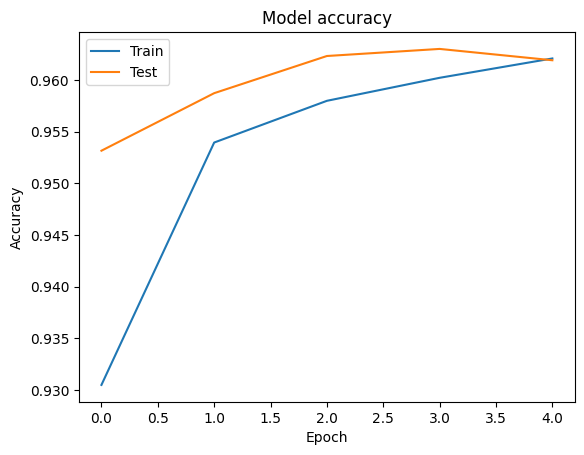

In [17]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

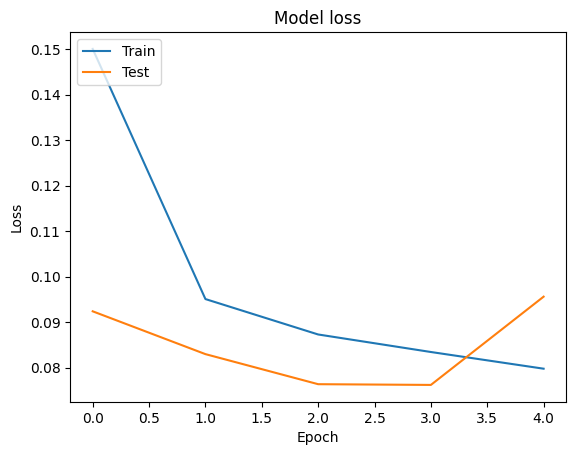

In [18]:
# Plot the training and validation loss over the epochs
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()
# plt.savefig('los_plo.jpg')

In [19]:
y_pred = model.predict(np.expand_dims(X_test, axis=2))

In [20]:
y_pred_classes = np.argmax(y_pred, axis=1)

# Inverse the 'attacks' dictionary to map back numbers to names
inverse_attacks = {v: k for k, v in attacks.items()}

# Generate the classification report with attack names instead of numbers
class_report = classification_report(y_test, y_pred_classes, target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))])

print(class_report)

                       precision    recall  f1-score   support

               Normal       1.00      1.00      1.00    560180
                 MITM       1.00      0.99      1.00       133
            Uploading       0.83      0.68      0.75     14756
           Ransomware       0.76      0.86      0.81      3952
        SQL_injection       0.55      0.88      0.67     20271
            DDoS_HTTP       0.95      0.85      0.90     19479
             DDoS_TCP       0.98      0.92      0.95     19942
             Password       0.72      0.37      0.49     19939
        Port_Scanning       0.80      0.98      0.88      7988
Vulnerability_scanner       0.99      0.92      0.95     20212
             Backdoor       0.94      0.88      0.91      9593
                  XSS       0.58      0.91      0.71      6128
       Fingerprinting       0.66      0.79      0.72       358
             DDoS_UDP       1.00      0.99      0.99     48340
            DDoS_ICMP       1.00      0.99      0.99  

In [21]:
# Get detailed report as a dictionary
report_dict = classification_report(
    y_test,
    y_pred_classes,
    target_names=[inverse_attacks[i] for i in range(len(inverse_attacks))],
    output_dict=True
)

# Convert to DataFrame and format with more floats
report_df = pd.DataFrame(report_dict).T  # transpose for better layout
report_df = report_df.round(4)  # round to 4 decimal places

print(report_df)

                       precision  recall  f1-score      support
Normal                    1.0000  1.0000    1.0000  560180.0000
MITM                      1.0000  0.9925    0.9962     133.0000
Uploading                 0.8257  0.6798    0.7457   14756.0000
Ransomware                0.7639  0.8565    0.8076    3952.0000
SQL_injection             0.5455  0.8768    0.6725   20271.0000
DDoS_HTTP                 0.9484  0.8507    0.8969   19479.0000
DDoS_TCP                  0.9756  0.9229    0.9485   19942.0000
Password                  0.7248  0.3720    0.4917   19939.0000
Port_Scanning             0.8006  0.9768    0.8800    7988.0000
Vulnerability_scanner     0.9908  0.9211    0.9547   20212.0000
Backdoor                  0.9398  0.8756    0.9066    9593.0000
XSS                       0.5828  0.9088    0.7102    6128.0000
Fingerprinting            0.6589  0.7877    0.7176     358.0000
DDoS_UDP                  0.9971  0.9908    0.9940   48340.0000
DDoS_ICMP                 0.9991  0.9892

In [22]:
# Binarize the true labels for multi-class AUC
y_test_bin = label_binarize(y_test, classes=list(attacks.values()))  # shape: (n_samples, n_classes)

# y_pred is already the softmax output: shape (n_samples, n_classes)
auc_macro = roc_auc_score(y_test_bin, y_pred, average='macro', multi_class='ovr')
auc_weighted = roc_auc_score(y_test_bin, y_pred, average='weighted', multi_class='ovr')

print(f"AUC (macro-averaged OvR): {auc_macro:.4f}")
print(f"AUC (weighted-averaged OvR): {auc_weighted:.4f}")

AUC (macro-averaged OvR): 0.9980
AUC (weighted-averaged OvR): 0.9993


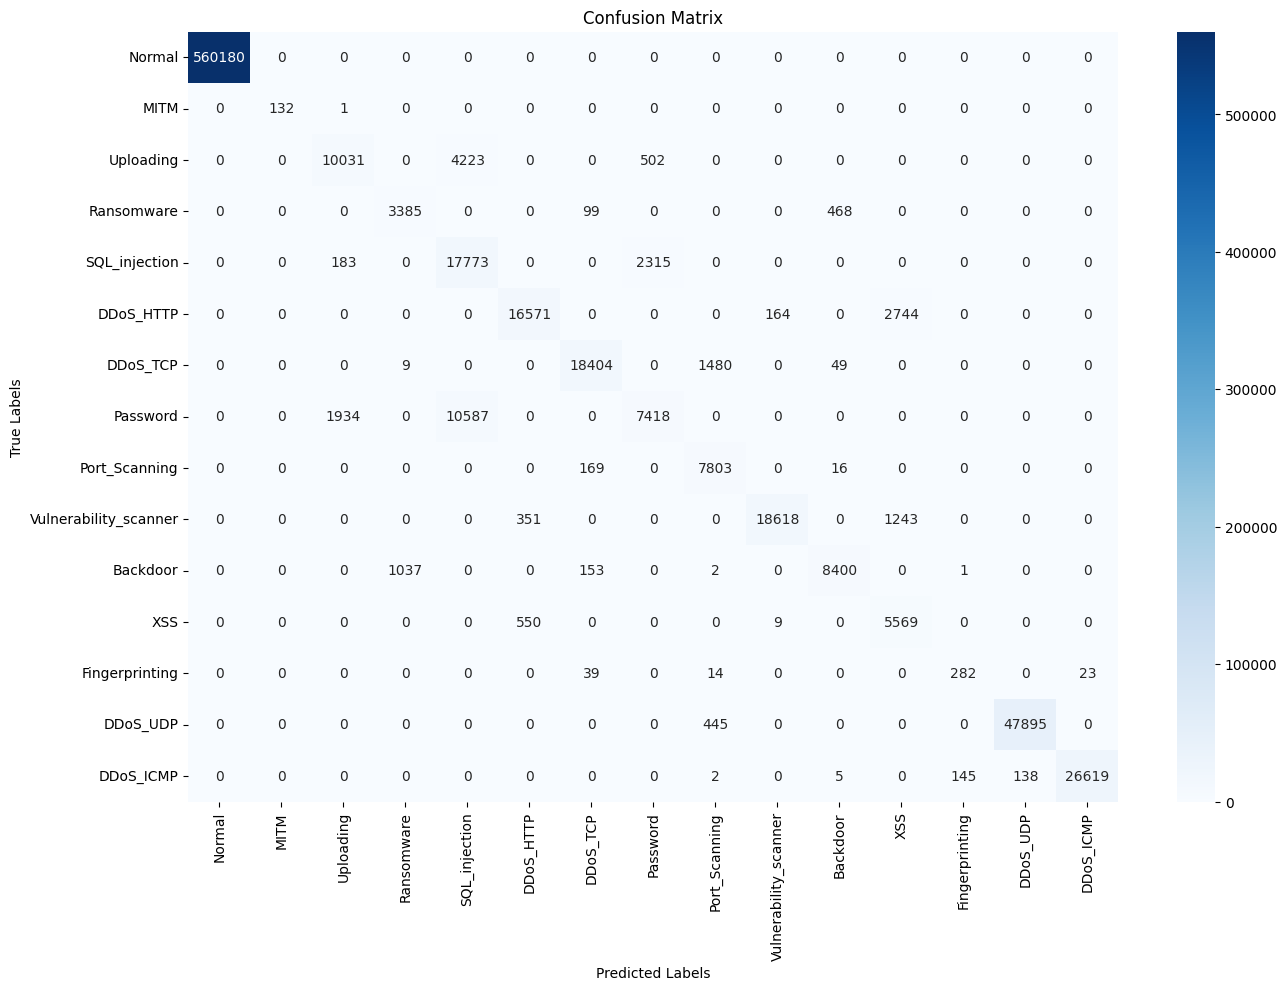

In [23]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat, annot=True, fmt="d", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
# plt.savefig('con_mat.jpg')

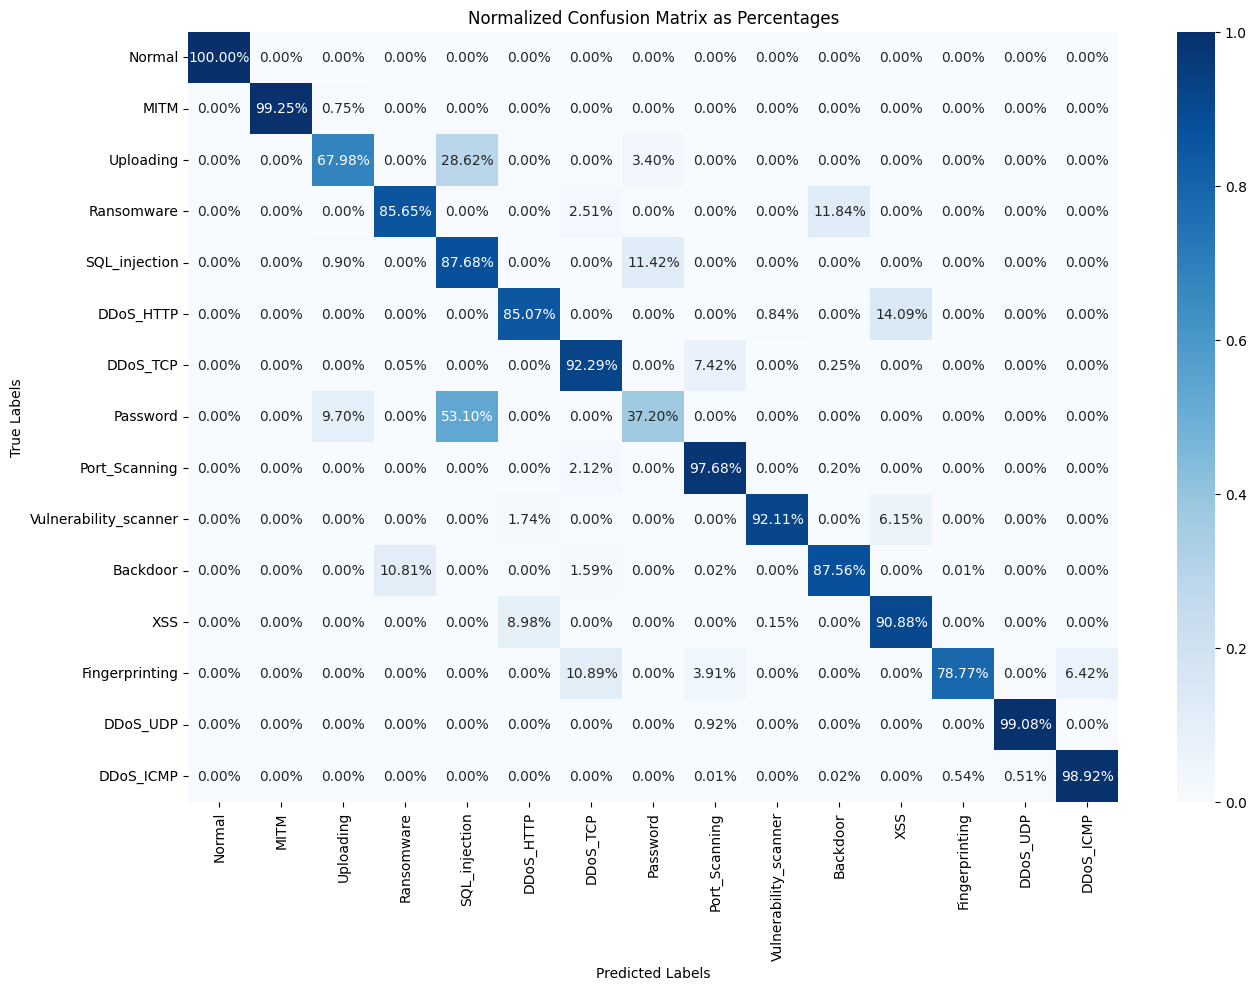

In [24]:
# Compute the confusion matrix
conf_mat = confusion_matrix(y_test, y_pred_classes)

# Normalize the confusion matrix by dividing each value by the sum of its row (i.e., the number of true instances for each label)
conf_mat_normalized = conf_mat.astype('float') / conf_mat.sum(axis=1)[:, np.newaxis]

# Convert the 'attacks' dictionary to a list of class names ordered by the class number
class_names_ordered = [attack for attack, number in sorted(attacks.items(), key=lambda item: item[1])]

# Plot the heatmap using seaborn
plt.figure(figsize=(15, 10))
sns.heatmap(conf_mat_normalized, annot=True, fmt=".2%", cmap="Blues", xticklabels=class_names_ordered, yticklabels=class_names_ordered)
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Normalized Confusion Matrix as Percentages')
plt.show()
# plt.savefig('con_per.jpg')